# 1. Multinomial Naive Bayes + CountVectorizer

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv('spam.csv', encoding='latin-1')

# Ambil kolom yang diperlukan
X = df['v2'].fillna('')
y = df['v1']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Model CountVectorizer + Multinomial Naive Bayes
model_count = Pipeline([
    ('vectorizer', CountVectorizer(stop_words='english')),
    ('classifier', MultinomialNB())
])

# Training
model_count.fit(X_train, y_train)

# Prediction
y_pred_count = model_count.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_count))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_count))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_count))

Accuracy: 0.9838565022421525

Confusion Matrix:
[[960   6]
 [ 12 137]]

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



# 2. Multinomial Naive Bayes + TF-IDF

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Model TF-IDF + Multinomial Naive Bayes
model_tfidf = Pipeline([
    ('vectorizer', TfidfVectorizer(stop_words='english')),
    ('classifier', MultinomialNB())
])

# Training
model_tfidf.fit(X_train, y_train)

# Prediction
y_pred_tfidf = model_tfidf.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred_tfidf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tfidf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tfidf))

Accuracy: 0.968609865470852

Confusion Matrix:
[[966   0]
 [ 35 114]]

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115



## Perbandingan CountVectorizer vs TF-IDF

| Metric          | CountVectorizer |   TF-IDF |
| --------------- | --------------: | -------: |
| Accuracy        |      **98.39%** |   96.86% |
| Spam Precision  |          95.80% | **100%** |
| Spam Recall     |      **91.95%** |   76.51% |
| Spam F1-score   |      **93.84%** |   86.69% |
| Spam terdeteksi |     **137/149** |  114/149 |
| Spam terlewat   |          **12** |   **35** |


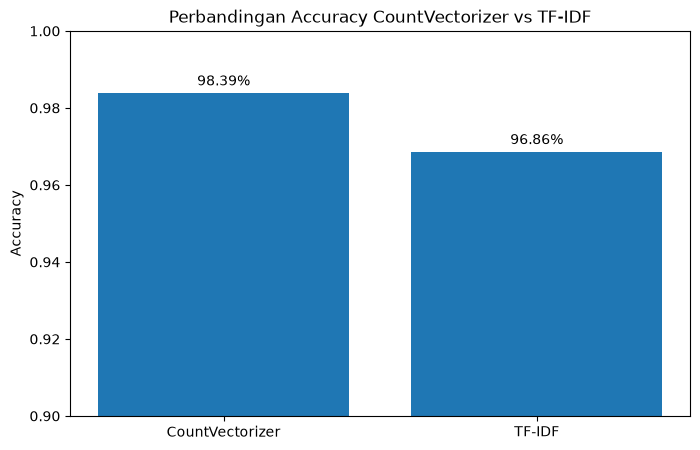

In [3]:
import matplotlib.pyplot as plt

models = ['CountVectorizer', 'TF-IDF']
accuracy = [
    accuracy_score(y_test, y_pred_count),
    accuracy_score(y_test, y_pred_tfidf)
]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracy)

plt.ylim(0.9, 1.0)
plt.ylabel('Accuracy')
plt.title('Perbandingan Accuracy CountVectorizer vs TF-IDF')

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.002,
        f'{value:.2%}',
        ha='center'
    )

plt.show()

Berdasarkan hasil pengujian, model Multinomial Naive Bayes dengan fitur CountVectorizer menghasilkan performa yang lebih baik dibandingkan dengan TF-IDF pada dataset spam.csv. CountVectorizer memperoleh accuracy sebesar 98.39%, sedangkan TF-IDF memperoleh accuracy sebesar 96.86%. Selain itu, CountVectorizer memiliki recall dan F1-score kelas spam yang lebih tinggi. Oleh karena itu, CountVectorizer merupakan fitur yang paling optimal untuk klasifikasi spam pada dataset ini.